# M3 — Data preprocessing and integrity validation
Synthetic ER, BA, SBM, directed ER; evidence from the completed real SNAP run.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'm34.py').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from m34 import normalize, encode, decode, pairs, build_records, pilot_graphs, FORMATS
%matplotlib inline
plt.rcParams.update({'figure.dpi': 80, 'figure.figsize': (5.4, 2.6), 'font.size': 9})

## Preserve direction and isolates; remove duplicate arcs and self-loops

In [2]:
g = nx.DiGraph()
g.add_edges_from([(10,20),(10,20),(20,20),(20,30)])
g.add_node(40)
h = normalize(g)
assert h.is_directed() and len(h)==4 and h.number_of_edges()==2 and nx.number_of_selfloops(h)==0
assert not h.has_edge(1,0) and 3 in h
print('Fixture passed:', pairs(h))

Fixture passed: [(0, 1), (1, 2)]


## Independent graphs, matched balanced queries and round-trip checks

In [3]:
cost, questions = build_records(pilot_graphs())
assert not set(questions[questions.split=='train'].graph_id) & set(questions[questions.split=='test'].graph_id)
assert cost.roundtrip.all()
print('Graph representations:',len(cost),'Unique graphs:',cost.graph_id.nunique())
print('Unique questions:', questions.question_id.nunique())
print(questions.groupby(['split','encoding','answer']).size().unstack(fill_value=0).to_string())

Graph representations: 720 Unique graphs: 180
Unique questions: 1440
answer            no  yes
split encoding           
test  adjacency  240  240
      compact    240  240
      edge_list  240  240
      natural    240  240
train adjacency  480  480
      compact    480  480
      edge_list  480  480
      natural    480  480


In [4]:
qid = questions.question_id.iloc[0]
for row in questions[questions.question_id==qid].itertuples():
    print(row.encoding, '\n', row.prompt[:350], '\nReference:', row.answer, '\n')

edge_list 
 Undirected; nodes: 0,1,2,3,4,5,6,7,8,9,10,11
(0, 4); (0, 5); (0, 8); (0, 10); (1, 6); (1, 9); (2, 3); (2, 5); (3, 5); (5, 10); (7, 9)
Are nodes 0 and 1 directly connected? Answer yes or no only. 
Reference: no 

adjacency 
 Undirected; nodes: 0,1,2,3,4,5,6,7,8,9,10,11
0: [4, 5, 8, 10]
1: [6, 9]
2: [3, 5]
3: [2, 5]
4: [0]
5: [0, 2, 3, 10]
6: [1]
7: [9]
8: [0]
9: [1, 7]
10: [0, 5]
11: []
Are nodes 0 and 1 directly connected? Answer yes or no only. 
Reference: no 

natural 
 Undirected; nodes: 0,1,2,3,4,5,6,7,8,9,10,11
Person 0 is friends with person 4. Person 0 is friends with person 5. Person 0 is friends with person 8. Person 0 is friends with person 10. Person 1 is friends with person 6. Person 1 is friends with person 9. Person 2 is friends with person 3. Person 2 is friends with person 5. Person 3 is friends with 
Reference: no 

compact 
 Undirected; nodes: 0,1,2,3,4,5,6,7,8,9,10,11
Each listed pair is an edge; unlisted rows have no stored edges.
0: [4, 5, 8, 10]
1: [6,

## Representation cost (not LLM tokenizer tokens)

           graphs  mean_bytes  lossless
encoding                               
adjacency     180     861.478       1.0
compact       180     680.967       1.0
edge_list     180    1121.200       1.0
natural       180    3738.117       1.0


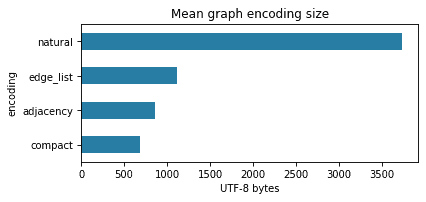

In [5]:
print(cost.groupby('encoding').agg(graphs=('graph_id','size'),mean_bytes=('bytes','mean'),lossless=('roundtrip','mean')).round(3).to_string())
cost.groupby('encoding').bytes.mean().sort_values().plot.barh(title='Mean graph encoding size', color='#287DA4')
plt.xlabel('UTF-8 bytes'); plt.tight_layout(); plt.show()

## Completed real-data run (19 November 2026)
The team ran Qwen2.5-0.5B-Instruct on real Facebook and Email-Eu-core data using `m34.py --mode llm --snap --limit 24` on an RTX 3050. Both dataset counts passed validation and all 96 predictions were saved. The notebook reads the actual saved CSVs; it does not rerun model inference.

The real-data path calls the M2 loader, samples induced subgraphs, preserves directions, removes self-loops for distinct-node questions, and verifies round-trip reconstruction before inference. Below, the saved results are checked for pairing and balance.

In [6]:
pred = pd.read_csv(ROOT / 'results/m34/llm_predictions.csv')
assert len(pred) == 96 and pred.question_id.nunique() == 24
assert pred.groupby('question_id').encoding.nunique().eq(4).all()
assert pred.groupby('question_id').truth.nunique().eq(1).all()
assert pred.groupby('encoding').truth.value_counts().eq(12).all()
print('Paired real-data checks passed:', len(pred), 'predictions,', pred.question_id.nunique(), 'questions')
print(pred.groupby(['family','encoding']).size().unstack().to_string())
print(pred.groupby(['encoding','truth']).size().unstack().to_string())

Paired real-data checks passed: 96 predictions, 24 questions
encoding              adjacency  compact  edge_list  natural
family                                                      
Email-Eu-core (SNAP)         14       14         14       14
Facebook (SNAP)              10       10         10       10
truth      no  yes
encoding          
adjacency  12   12
compact    12   12
edge_list  12   12
natural    12   12
